<a href="https://colab.research.google.com/github/rahuldevagiri/deep-learning-project/blob/main/01_global_data_collection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1.3

In [2]:
import ee, pandas as pd
PROJECT_ID = "deep-learning-27"          # replace
try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate(force=True)
    ee.Initialize(project=PROJECT_ID)

LAT, LON = 49.3988, 8.6724                     # Heidelberg
pt = ee.Geometry.Point([LON, LAT])
col = (ee.ImageCollection("COPERNICUS/S1_GRD")
       .filterBounds(pt).filterDate("2025-10-01", "2026-10-01")
       .filter(ee.Filter.eq("instrumentMode", "IW")))

hd = pd.DataFrame({
    "id":   col.aggregate_array("system:index").getInfo(),
    "date": pd.to_datetime(col.aggregate_array("system:time_start").getInfo(), unit="ms"),
    "pass": col.aggregate_array("orbitProperties_pass").getInfo(),
    "sat":  col.aggregate_array("platform_number").getInfo()})
print(len(hd), "images"); print(hd.sat.value_counts())
hd.head(10)

195 images
sat
C    87
A    66
D    42
Name: count, dtype: int64


,id,date,pass,sat
0,S1A_IW_GRDH_1SDV_20251005T054243_20251005T0543...,2025-10-05 05:42:43,DESCENDING,A
1,S1A_IW_GRDH_1SDV_20251008T171624_20251008T1716...,2025-10-08 17:16:24,ASCENDING,A
2,S1A_IW_GRDH_1SDV_20251012T053446_20251012T0535...,2025-10-12 05:34:46,DESCENDING,A
3,S1A_IW_GRDH_1SDV_20251017T054244_20251017T0543...,2025-10-17 05:42:44,DESCENDING,A
4,S1A_IW_GRDH_1SDV_20251020T171624_20251020T1716...,2025-10-20 17:16:24,ASCENDING,A
5,S1A_IW_GRDH_1SDV_20251024T053446_20251024T0535...,2025-10-24 05:34:46,DESCENDING,A
6,S1A_IW_GRDH_1SDV_20251029T054243_20251029T0543...,2025-10-29 05:42:43,DESCENDING,A
7,S1A_IW_GRDH_1SDV_20251101T171623_20251101T1716...,2025-11-01 17:16:23,ASCENDING,A
8,S1A_IW_GRDH_1SDV_20251105T053445_20251105T0535...,2025-11-05 05:34:45,DESCENDING,A
9,S1A_IW_GRDH_1SDV_20251110T054243_20251110T0543...,2025-11-10 05:42:43,DESCENDING,A


Extra work to check the images for Heidelberg

In [5]:
col = (ee.ImageCollection("COPERNICUS/S1_GRD")
       .filterBounds(pt).filterDate("2025-10-01", "2026-10-01")
       .filter(ee.Filter.eq("instrumentMode", "IW")))
import pandas as pd
hd = pd.DataFrame({
    "id":    col.aggregate_array("system:index").getInfo(),
    "date":  pd.to_datetime(col.aggregate_array("system:time_start").getInfo(), unit="ms"),
    "pass":  col.aggregate_array("orbitProperties_pass").getInfo(),
    "sat":   col.aggregate_array("platform_number").getInfo()})
print(len(hd), "images"); print(hd.sat.value_counts()); hd.head(10)

195 images
sat
C    87
A    66
D    42
Name: count, dtype: int64


,id,date,pass,sat
0,S1A_IW_GRDH_1SDV_20251005T054243_20251005T0543...,2025-10-05 05:42:43,DESCENDING,A
1,S1A_IW_GRDH_1SDV_20251008T171624_20251008T1716...,2025-10-08 17:16:24,ASCENDING,A
2,S1A_IW_GRDH_1SDV_20251012T053446_20251012T0535...,2025-10-12 05:34:46,DESCENDING,A
3,S1A_IW_GRDH_1SDV_20251017T054244_20251017T0543...,2025-10-17 05:42:44,DESCENDING,A
4,S1A_IW_GRDH_1SDV_20251020T171624_20251020T1716...,2025-10-20 17:16:24,ASCENDING,A
5,S1A_IW_GRDH_1SDV_20251024T053446_20251024T0535...,2025-10-24 05:34:46,DESCENDING,A
6,S1A_IW_GRDH_1SDV_20251029T054243_20251029T0543...,2025-10-29 05:42:43,DESCENDING,A
7,S1A_IW_GRDH_1SDV_20251101T171623_20251101T1716...,2025-11-01 17:16:23,ASCENDING,A
8,S1A_IW_GRDH_1SDV_20251105T053445_20251105T0535...,2025-11-05 05:34:45,DESCENDING,A
9,S1A_IW_GRDH_1SDV_20251110T054243_20251110T0543...,2025-11-10 05:42:43,DESCENDING,A


In [6]:
import geemap
m = geemap.Map(center=[LAT, LON], zoom=12)
vv = col.filterDate("2026-09-01", "2026-10-01").select("VV").median()
m.addLayer(vv, {"min": -25, "max": 0}, "VV median Sep 2026")
m.addLayer(ee.ImageCollection("ESA/WorldCover/v200").first(), {"bands": ["Map"]}, "WorldCover 2021", False)
m

Map(center=[49.3988, 8.6724], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

Cell 1.4

In [7]:
from google.colab import drive
drive.mount("/content/drive")
import os
os.makedirs("/content/drive/MyDrive/lulc_s1_global", exist_ok=True)
print("Drive OK")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive OK


Cell 2.1

In [ ]:
import ee, json, hashlib, os
import pandas as pd
import matplotlib.pyplot as plt
ee.Initialize(project="deep-learning-27")

FROM = [10, 20, 30, 40, 50, 60,  70, 80, 90, 95, 100]
TO   = [ 0,  1,  1,  2,  3,  4, 255,  5,  6,  0,   1]
CLASSES = ["Tree", "Shrub/Grass", "Cropland", "Built-up", "Bare", "Water", "Wetland"]

def label_image():
    return (ee.ImageCollection("ESA/WorldCover/v200").first()
            .remap(FROM, TO, 255).rename("label"))

CONTINENTS = {   # [West, South, East, North]
    "europe":    [-11,  35,  40,  71],
    "africa":    [-18, -35,  52,  37],
    "asia":      [ 40,   5, 150,  60],
    "n_america": [-130, 15, -55,  60],
    "s_america": [-82, -56, -34,  13],
    "oceania":   [112, -45, 180, -10],
}
PER_CLASS = {0: 40, 1: 40, 2: 40, 3: 70, 4: 30, 5: 40, 6: 30}   # Built-up oversampled

Cell 2.2

In [ ]:
lab = label_image()
points = []
for cont, bbox in CONTINENTS.items():
    try:
        fc = lab.stratifiedSample(
            numPoints=0, classBand="label", region=ee.Geometry.BBox(*bbox),
            scale=500, seed=42, geometries=True, tileScale=16,
            classValues=list(PER_CLASS.keys()),
            classPoints=list(PER_CLASS.values()))
        feats = fc.getInfo()["features"]
    except Exception as e:
        print(cont, "FAILED:", e)
        continue
    for f in feats:
        lon, lat = f["geometry"]["coordinates"]
        points.append({"lat": lat, "lon": lon,
                       "cls": int(f["properties"]["label"]), "cont": cont})
    print(f"{cont}: {len(feats)} points")
print("TOTAL:", len(points))

europe: 290 points
africa: 290 points
asia: 290 points
n_america: 290 points
s_america: 290 points
oceania: 290 points
TOTAL: 1740


Cell 2.3

cls_name   Bare  Built-up  Cropland  Shrub/Grass  Tree  Water  Wetland   All
cont                                                                        
africa       30        70        40           40    40     40       30   290
asia         30        70        40           40    40     40       30   290
europe       30        70        40           40    40     40       30   290
n_america    30        70        40           40    40     40       30   290
oceania      30        70        40           40    40     40       30   290
s_america    30        70        40           40    40     40       30   290
All         180       420       240          240   240    240      180  1740 

cls_name  Bare  Built-up  Cropland  Shrub/Grass  Tree  Water  Wetland   All
split                                                                      
test        10        66        44           20    36     31       17   224
train      147       292       160          193   169    173      123  1257
v

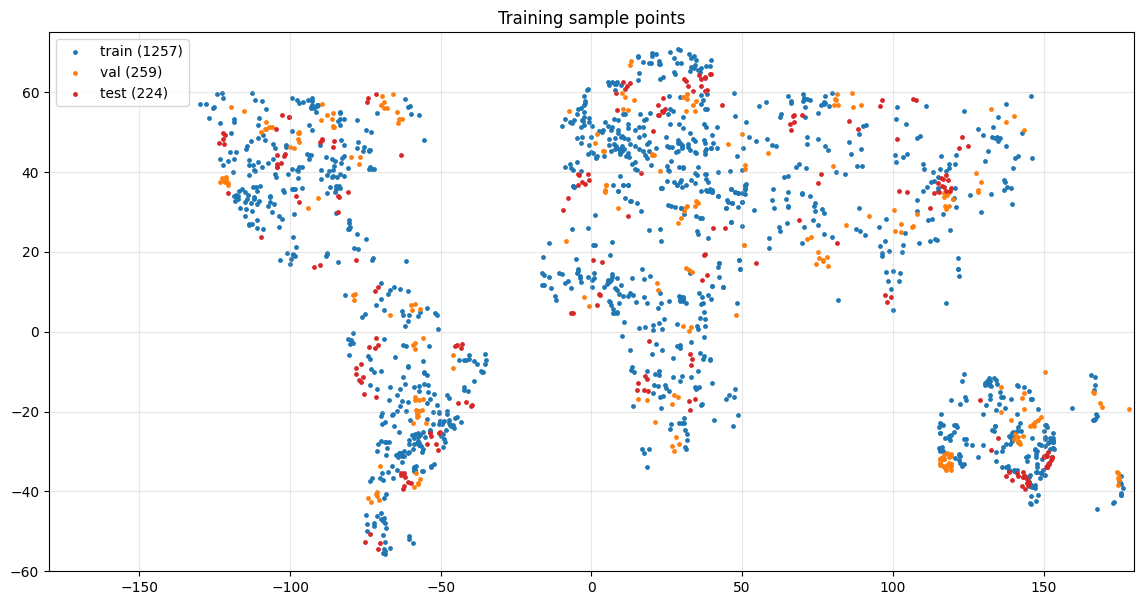

Saved 1740 points to /content/drive/MyDrive/lulc_s1_global/points.json


In [ ]:
def split_for(lat, lon):
    cell = f"{int(lat // 5)}_{int(lon // 5)}"
    h = int(hashlib.md5(cell.encode()).hexdigest(), 16) % 100
    return "train" if h < 70 else "val" if h < 85 else "test"

df = pd.DataFrame(points)
df["split"] = [split_for(a, b) for a, b in zip(df.lat, df.lon)]
df["cls_name"] = df.cls.map(dict(enumerate(CLASSES)))

print(pd.crosstab(df.cont, df.cls_name, margins=True), "\n")
print(pd.crosstab(df.split, df.cls_name, margins=True), "\n")

plt.figure(figsize=(14, 7))
for s, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red")]:
    d = df[df.split == s]
    plt.scatter(d.lon, d.lat, s=6, c=c, label=f"{s} ({len(d)})")
plt.xlim(-180, 180); plt.ylim(-60, 75); plt.grid(alpha=.3)
plt.legend(); plt.title("Training sample points"); plt.show()

OUT = "/content/drive/MyDrive/lulc_s1_global"
df.to_json(f"{OUT}/points.json", orient="records")
print("Saved", len(df), "points to", f"{OUT}/points.json")

Cell 3.1

In [ ]:
import numpy as np, time
from pyproj import Transformer
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

YEAR_START = "2021-01-01"
T, RES, NODATA = 256, 10, -32768
OUT = "/content/drive/MyDrive/lulc_s1_global"

def s1_collection(region, start, end):
    """All S1 IW VV+VH images, both orbit directions, swath edges masked."""
    def mask_edges(img):
        a = img.select("angle")
        return img.updateMask(a.gt(30.6).And(a.lt(45.2)))
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(region).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
            .map(mask_edges).select(["VV", "VH"]))

def monthly_composite(region, start, i):
    s = ee.Date(start).advance(i, "month")
    col = s1_collection(region, s, s.advance(1, "month"))
    empty = ee.Image.constant([0, 0]).rename(["VV", "VH"]).updateMask(0)
    img = ee.Image(ee.Algorithms.If(col.size().gt(0), col.median(), empty))
    return (img.multiply(100).round().unmask(NODATA).toInt16()
               .rename([f"VV_{i:02d}", f"VH_{i:02d}"]))

def utm_epsg(lat, lon):
    z = int((lon + 180) / 6) + 1
    return f"EPSG:{32600 + z if lat >= 0 else 32700 + z}"

pts = pd.read_json(f"{OUT}/points.json").to_dict("records")
for s in ("train", "val", "test"):
    os.makedirs(f"{OUT}/patches/{s}", exist_ok=True)

def fetch(idx, p, retries=3):
    path = f"{OUT}/patches/{p['split']}/p{idx:05d}.npz"
    if os.path.exists(path):
        return "skip"
    crs = utm_epsg(p["lat"], p["lon"])
    x, y = Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(p["lon"], p["lat"])
    x0 = round(x / RES) * RES - T * RES // 2
    y0 = round(y / RES) * RES + T * RES // 2
    region = ee.Geometry.Point([p["lon"], p["lat"]]).buffer(2000).bounds()
    label = label_image().unmask(255).toInt16()          # masked pixels -> ignore, not class 0
    stack = ee.Image.cat([monthly_composite(region, YEAR_START, i) for i in range(12)] + [label])
    req = {"expression": stack, "fileFormat": "NUMPY_NDARRAY",
           "grid": {"dimensions": {"width": T, "height": T}, "crsCode": crs,
                    "affineTransform": {"scaleX": RES, "shearX": 0, "translateX": x0,
                                        "shearY": 0, "scaleY": -RES, "translateY": y0}}}
    for a in range(retries):
        try:
            arr = ee.data.computePixels(req)
            break
        except Exception as e:
            err = str(e)
            time.sleep(5 * (a + 1))
    else:
        return f"fail {idx}: {err[:150]}"
    s1 = np.stack([arr[f"{b}_{i:02d}"] for i in range(12) for b in ("VV", "VH")]).reshape(12, 2, T, T)
    np.savez_compressed(path, x=s1, y=arr["label"].astype(np.uint8),
                        lat=p["lat"], lon=p["lon"], cls=p["cls"], cont=p["cont"])
    return "ok"

Cell 3.2

['skip', 'skip', 'skip']
x (12, 2, 256, 256) int16 | y (256, 256) | classes: [0 1 6]
VV dB range (July): -15.69 -7.19


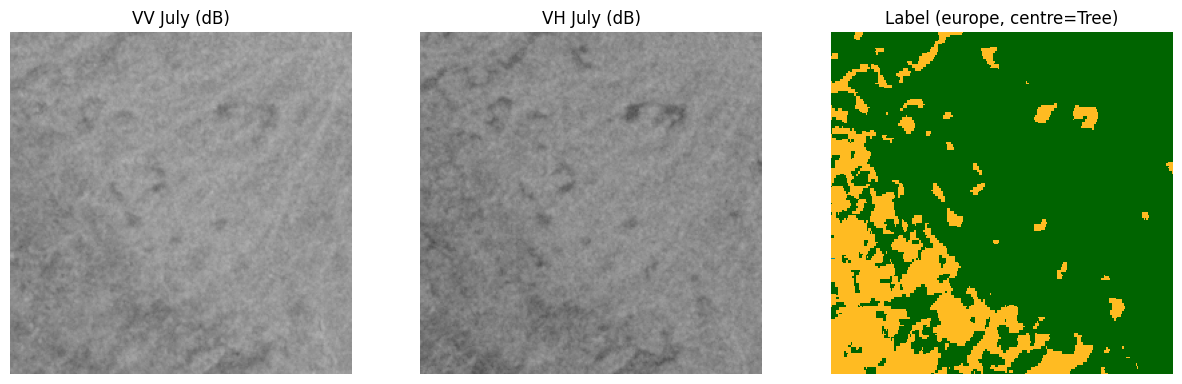

In [ ]:
from matplotlib.colors import ListedColormap
print([fetch(i, pts[i]) for i in range(3)])

d = np.load(f"{OUT}/patches/{pts[0]['split']}/p00000.npz")
x, y = d["x"], d["y"]
print("x", x.shape, x.dtype, "| y", y.shape, "| classes:", np.unique(y))
print("VV dB range (July):", x[6, 0].min() / 100, x[6, 0].max() / 100)

COLORS = ["#006400", "#ffbb22", "#f096ff", "#fa0000", "#b4b4b4", "#0064c8", "#0096a0"]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(x[6, 0] / 100, cmap="gray", vmin=-25, vmax=0); ax[0].set_title("VV July (dB)")
ax[1].imshow(x[6, 1] / 100, cmap="gray", vmin=-30, vmax=-5); ax[1].set_title("VH July (dB)")
ax[2].imshow(np.ma.masked_equal(y, 255), cmap=ListedColormap(COLORS), vmin=0, vmax=6, interpolation="nearest")
ax[2].set_title(f"Label ({pts[0]['cont']}, centre={CLASSES[pts[0]['cls']]})")
for a in ax: a.axis("off")
plt.show()

Cell 3.3

In [ ]:
results = []
with ThreadPoolExecutor(8) as ex:
    futs = [ex.submit(fetch, i, p) for i, p in enumerate(pts)]
    for f in tqdm(as_completed(futs), total=len(futs)):
        results.append(f.result())

fails = [r for r in results if r.startswith("fail")]
print("ok:", results.count("ok"), "| skip:", results.count("skip"), "| fail:", len(fails))
print("\n".join(fails[:10]))

  0%|          | 0/1740 [00:00<?, ?it/s]

ok: 0 | skip: 1740 | fail: 0



Cell 4.1

In [ ]:
import glob, json
CLIP = {"VV": [-30.0, 5.0], "VH": [-35.0, -5.0]}
SPLITS = ("train", "val", "test")

files = sorted(glob.glob(f"{OUT}/patches/*/*.npz"))
print("files:", len(files))

rows = []
cls_count = {s: np.zeros(7, np.int64) for s in SPLITS}
sums, sqs, n = np.zeros(3), np.zeros(3), 0

for f in tqdm(files):
    split = f.split("/")[-2]
    d = np.load(f); x, y = d["x"], d["y"]
    cls_count[split] += np.bincount(y[y != 255], minlength=7)[:7]
    for m in range(12):
        if (x[m] == NODATA).mean() > 0.01:          # skip months with gaps
            continue
        rows.append({"path": f, "split": split, "month": m,
                     "lat": float(d["lat"]), "lon": float(d["lon"])})
        if split == "train":                          # stats from train only
            ok = (x[m, 0] != NODATA) & (x[m, 1] != NODATA)
            vv = np.clip(x[m, 0] / 100, *CLIP["VV"])[ok]
            vh = np.clip(x[m, 1] / 100, *CLIP["VH"])[ok]
            feats = np.stack([vv, vh, vv - vh])
            sums += feats.sum(1); sqs += (feats ** 2).sum(1); n += feats.shape[1]

idx = pd.DataFrame(rows)
idx.to_csv(f"{OUT}/index.csv", index=False)
print("\nsamples (patch x month) per split:\n", idx.groupby("split").size())
print("patches with < 12 valid months:", (idx.groupby("path").size() < 12).sum())

files: 1740


  0%|          | 0/1740 [00:00<?, ?it/s]


samples (patch x month) per split:
 split
test      2678
train    14827
val       3070
dtype: int64
patches with < 12 valid months: 57


Cell 4.2

In [ ]:
cc = pd.DataFrame(cls_count, index=CLASSES)
print("Pixel share per class (%):\n", (cc / cc.sum() * 100).round(2))

mean = sums / n
std = np.sqrt(sqs / n - mean ** 2)
freq = cls_count["train"] / cls_count["train"].sum()
weights = np.clip(np.median(freq) / freq, 0.2, 10)        # median-frequency balancing

stats = {"channels": ["VV", "VH", "VV-VH"], "clip": CLIP,
         "mean": mean.round(4).tolist(), "std": std.round(4).tolist(),
         "classes": CLASSES, "colors": COLORS,
         "class_weights": weights.round(4).tolist(),
         "nodata": NODATA, "scale": 100, "ignore_index": 255}
json.dump(stats, open(f"{OUT}/norm_stats.json", "w"), indent=2)
print(json.dumps(stats, indent=2))

Pixel share per class (%):
              train    val   test
Tree         21.44  22.09  25.19
Shrub/Grass  26.60  21.88  21.22
Cropland     13.08  16.26  18.32
Built-up      9.17   8.51  11.98
Bare          9.77   7.56   4.92
Water        14.51  14.40  14.67
Wetland       5.43   9.30   3.69
{
  "channels": [
    "VV",
    "VH",
    "VV-VH"
  ],
  "clip": {
    "VV": [
      -30.0,
      5.0
    ],
    "VH": [
      -35.0,
      -5.0
    ]
  },
  "mean": [
    -12.47,
    -20.2292,
    7.7593
  ],
  "std": [
    4.8594,
    5.6416,
    2.8911
  ],
  "classes": [
    "Tree",
    "Shrub/Grass",
    "Cropland",
    "Built-up",
    "Bare",
    "Water",
    "Wetland"
  ],
  "colors": [
    "#006400",
    "#ffbb22",
    "#f096ff",
    "#fa0000",
    "#b4b4b4",
    "#0064c8",
    "#0096a0"
  ],
  "class_weights": [
    0.61,
    0.4915,
    1.0,
    1.4254,
    1.3384,
    0.9011,
    2.4098
  ],
  "nodata": -32768,
  "scale": 100,
  "ignore_index": 255
}


Cell 4.3

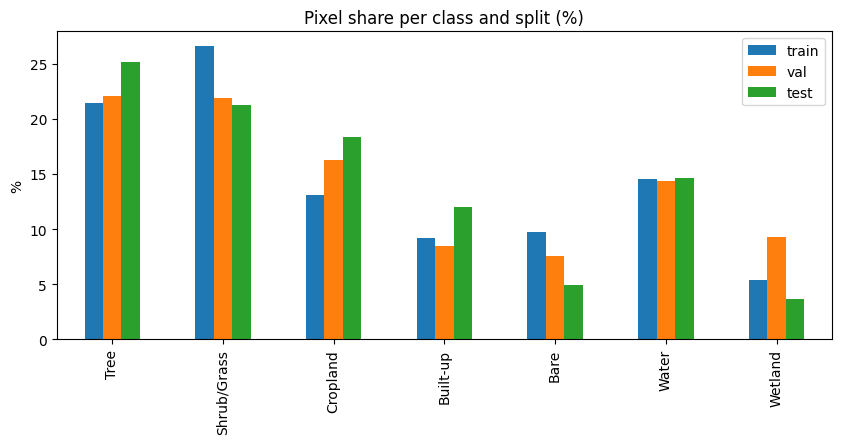

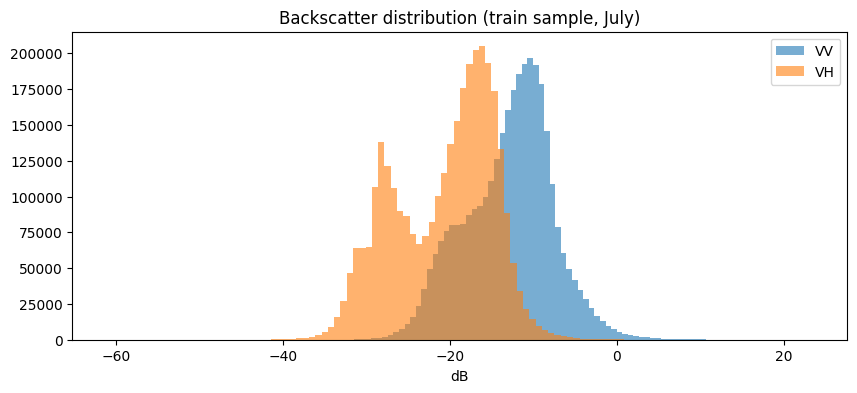

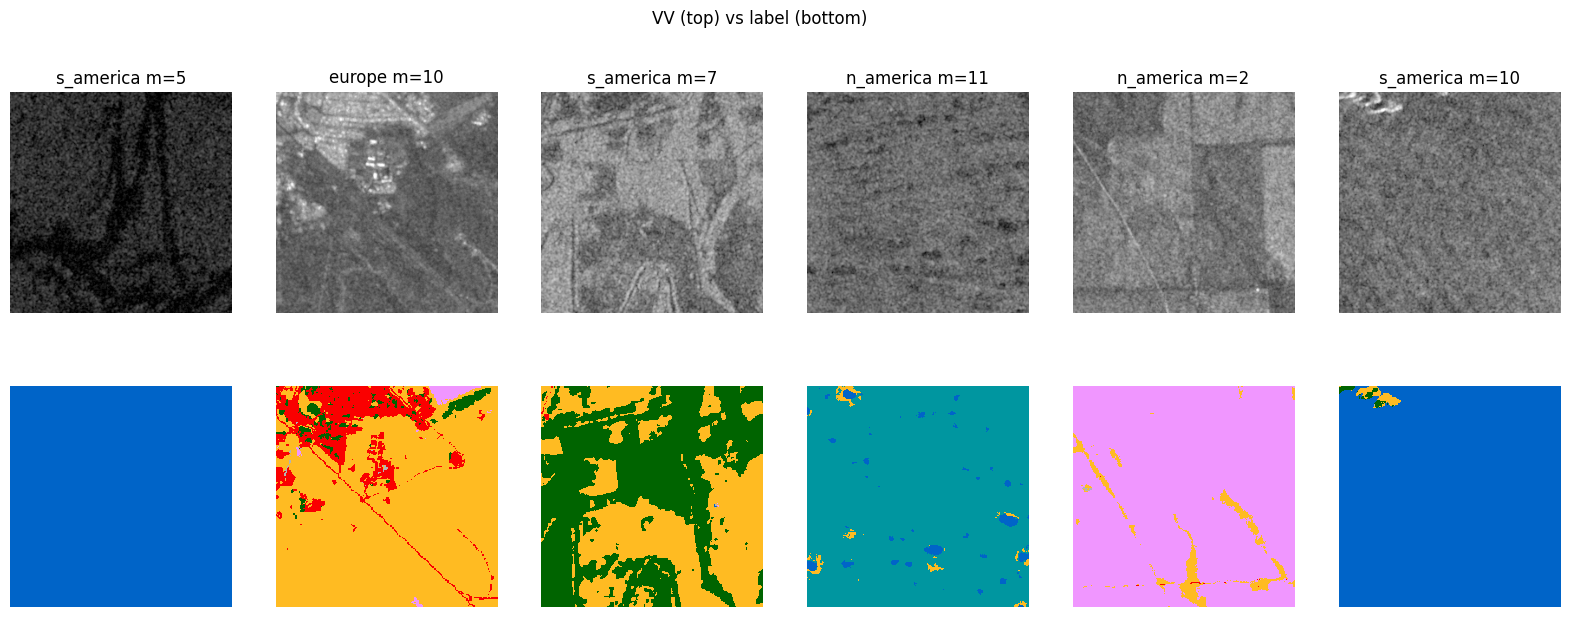

In [ ]:
# Class distribution chart
(cc / cc.sum() * 100).plot.bar(figsize=(10, 4), title="Pixel share per class and split (%)")
plt.ylabel("%"); plt.show()

# Backscatter histograms (sample of 50 train patches, July)
tr = idx[(idx.split == "train") & (idx.month == 6)].sample(50, random_state=0)
vv_all, vh_all = [], []
for p in tr.path:
    x = np.load(p)["x"][6]
    vv_all.append(x[0][x[0] != NODATA] / 100); vh_all.append(x[1][x[1] != NODATA] / 100)
plt.figure(figsize=(10, 4))
plt.hist(np.concatenate(vv_all), bins=100, alpha=.6, label="VV")
plt.hist(np.concatenate(vh_all), bins=100, alpha=.6, label="VH")
plt.xlabel("dB"); plt.legend(); plt.title("Backscatter distribution (train sample, July)"); plt.show()

# 6 random patches: VV + label
cmap = ListedColormap(COLORS)
smp = idx.sample(6, random_state=1)
fig, ax = plt.subplots(2, 6, figsize=(20, 7))
for k, (_, r) in enumerate(smp.iterrows()):
    d = np.load(r.path)
    ax[0, k].imshow(d["x"][r.month, 0] / 100, cmap="gray", vmin=-25, vmax=0)
    ax[0, k].set_title(f"{d['cont']} m={r.month + 1}")
    ax[1, k].imshow(np.ma.masked_equal(d["y"], 255), cmap=cmap, vmin=0, vmax=6, interpolation="nearest")
for a in ax.ravel(): a.axis("off")
plt.suptitle("VV (top) vs label (bottom)"); plt.show()

Cell 4.4

In [ ]:
!du -sh {OUT}/patches

3.8G	/content/drive/MyDrive/lulc_s1_global/patches


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
images per month: {'2025-10': 15, '2025-11': 14, '2025-12': 16, '2026-01': 15, '2026-02': 14, '2026-03': 16, '2026-04': 18, '2026-05': 21, '2026-06': 19, '2026-07': 15, '2026-08': 17, '2026-09': 15} | total: 195


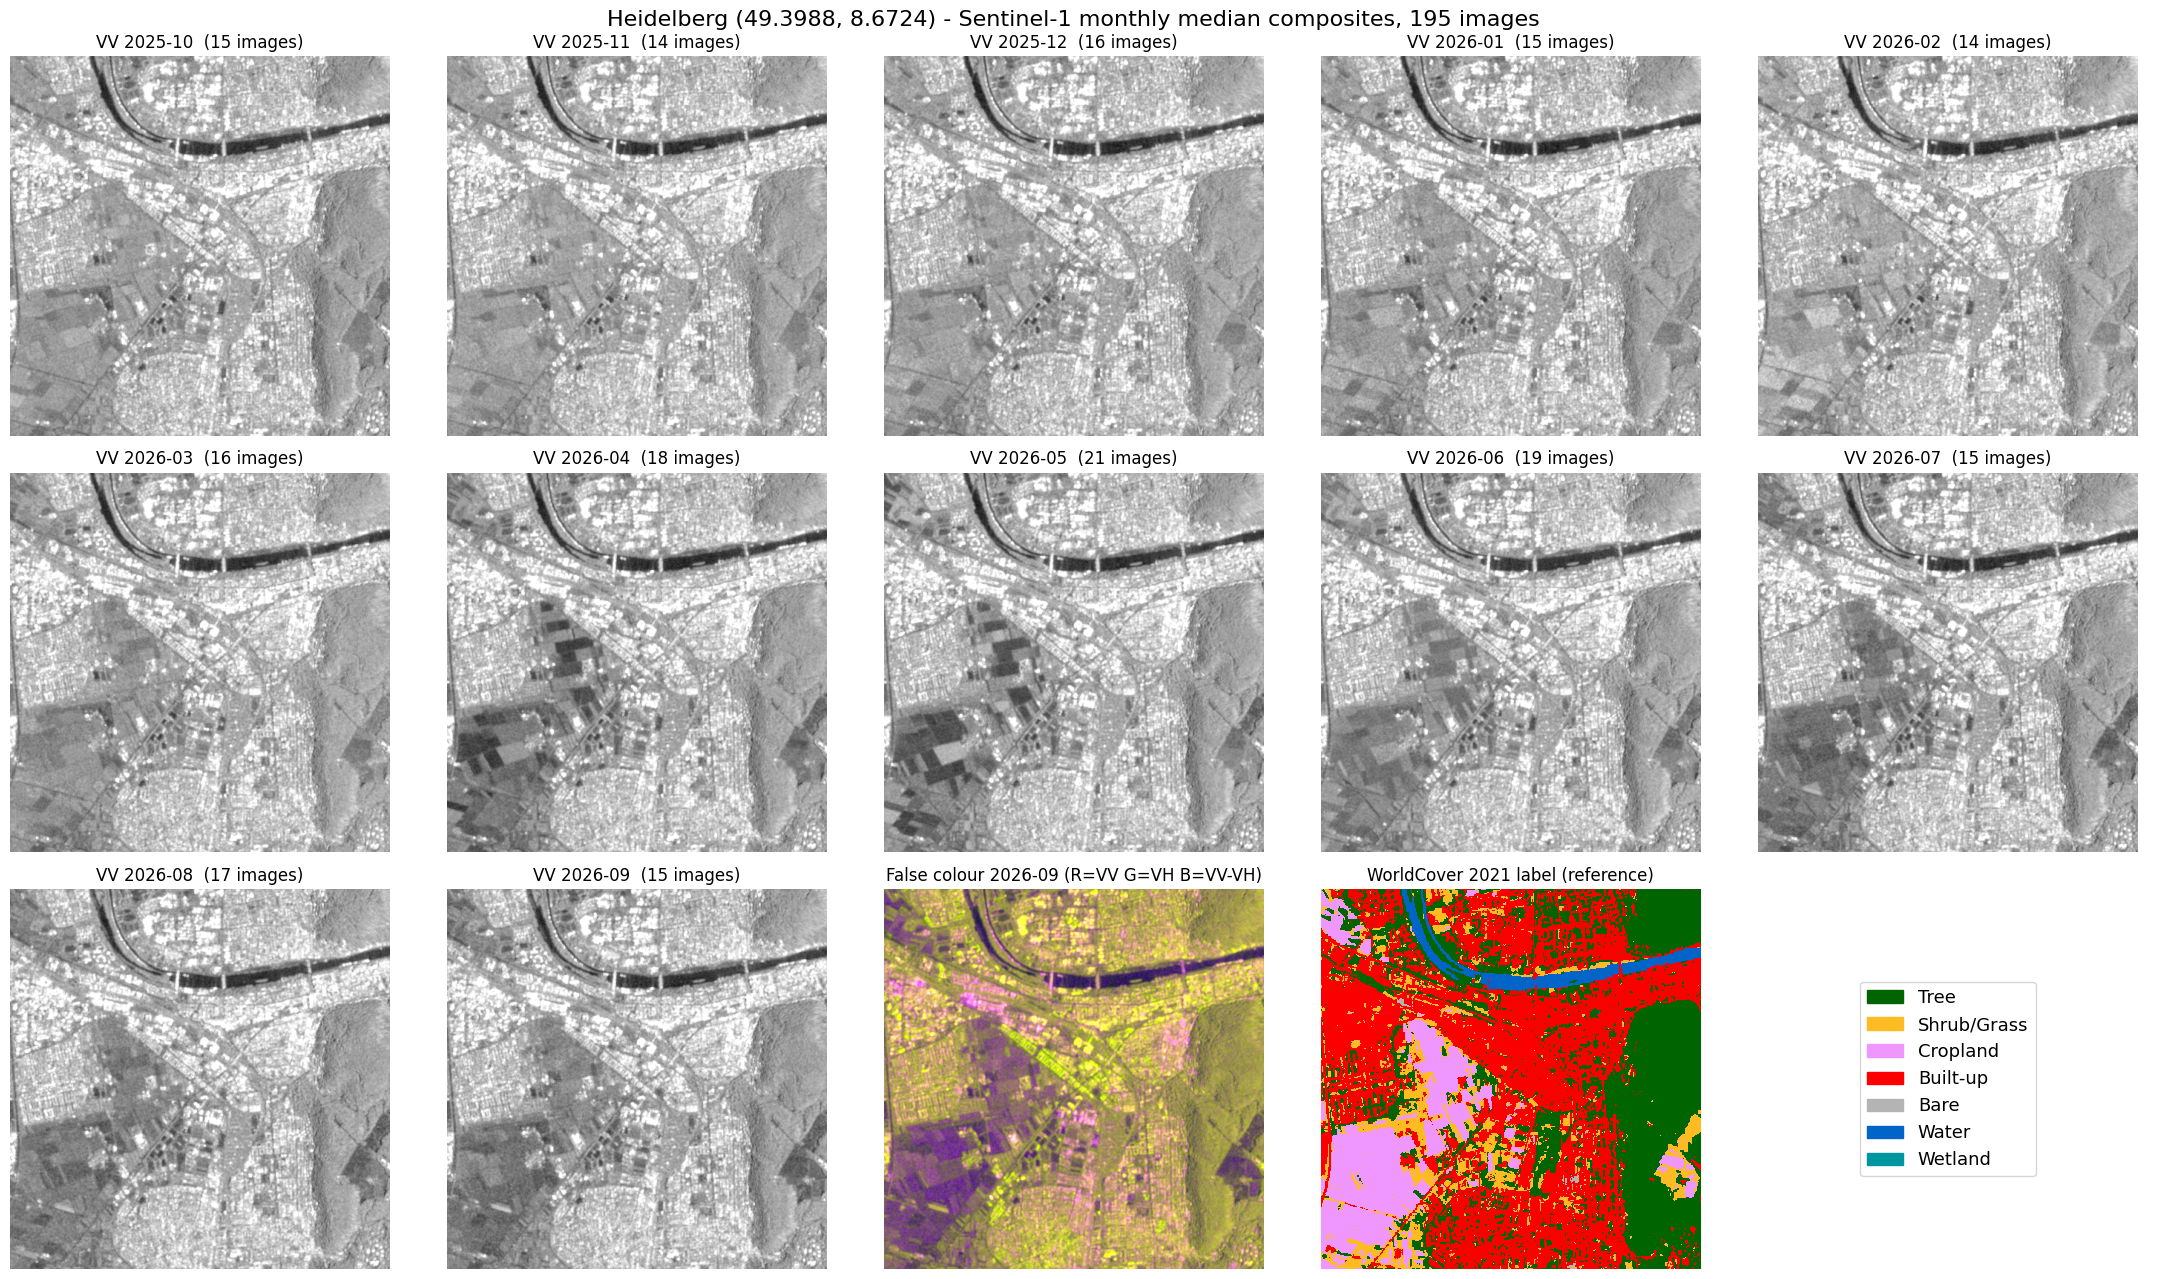

saved to /content/drive/MyDrive/lulc_s1_global/heidelberg


In [3]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pyproj import Transformer
from google.colab import drive
drive.mount("/content/drive")

LAT, LON, NAME = 49.3988, 8.6724, "heidelberg"
START, T, RES, NODATA = "2025-10-01", 512, 10, -32768      # 512 px = 5.12 km
FROM = [10, 20, 30, 40, 50, 60,  70, 80, 90, 95, 100]
TO   = [ 0,  1,  1,  2,  3,  4, 255,  5,  6,  0,   1]
CLASSES = ["Tree", "Shrub/Grass", "Cropland", "Built-up", "Bare", "Water", "Wetland"]
COLORS  = ["#006400", "#ffbb22", "#f096ff", "#fa0000", "#b4b4b4", "#0064c8", "#0096a0"]

def s1_collection(region, start, end):
    def mask_edges(img):
        a = img.select("angle")
        return img.updateMask(a.gt(30.6).And(a.lt(45.2)))
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(region).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
            .map(mask_edges).select(["VV", "VH"]))

def monthly_composite(region, start, i):
    s = ee.Date(start).advance(i, "month")
    col = s1_collection(region, s, s.advance(1, "month"))
    empty = ee.Image.constant([0, 0]).rename(["VV", "VH"]).updateMask(0)
    img = ee.Image(ee.Algorithms.If(col.size().gt(0), col.median(), empty))
    return (img.multiply(100).round().unmask(NODATA).toInt16()
               .rename([f"VV_{i:02d}", f"VH_{i:02d}"]))

def utm_epsg(lat, lon):
    z = int((lon + 180) / 6) + 1
    return f"EPSG:{32600 + z if lat >= 0 else 32700 + z}"

# --- download ---
region = ee.Geometry.Point([LON, LAT]).buffer(4000).bounds()
crs = utm_epsg(LAT, LON)
x, y = Transformer.from_crs("EPSG:4326", crs, always_xy=True).transform(LON, LAT)
x0, y0 = round(x / RES) * RES - T * RES // 2, round(y / RES) * RES + T * RES // 2
label = (ee.ImageCollection("ESA/WorldCover/v200").first()
         .remap(FROM, TO, 255).unmask(255).toInt16().rename("label"))
stack = ee.Image.cat([monthly_composite(region, START, i) for i in range(12)] + [label])
arr = ee.data.computePixels({
    "expression": stack, "fileFormat": "NUMPY_NDARRAY",
    "grid": {"dimensions": {"width": T, "height": T}, "crsCode": crs,
             "affineTransform": {"scaleX": RES, "shearX": 0, "translateX": x0,
                                 "shearY": 0, "scaleY": -RES, "translateY": y0}}})
s1 = np.stack([arr[f"{b}_{i:02d}"] for i in range(12) for b in ("VV", "VH")]).reshape(12, 2, T, T)
lab = arr["label"].astype(np.uint8)

s = ee.Date(START)
counts = ee.List.sequence(0, 11).map(lambda i: s1_collection(
    region, s.advance(i, "month"), s.advance(ee.Number(i).add(1), "month")).size()).getInfo()
months = pd.date_range(START, periods=12, freq="MS").strftime("%Y-%m").tolist()
print("images per month:", dict(zip(months, counts)), "| total:", sum(counts))

# --- save data to Drive ---
OUTH = "/content/drive/MyDrive/lulc_s1_global/heidelberg"; os.makedirs(OUTH, exist_ok=True)
np.savez_compressed(f"{OUTH}/{NAME}_{months[0]}_{months[-1]}.npz",
                    x=s1, y=lab, months=months, counts=counts, lat=LAT, lon=LON)

# --- plot: 12 months VV + false colour + label + legend ---
fig, ax = plt.subplots(3, 5, figsize=(22, 13)); ax = ax.ravel()
for i in range(12):
    ax[i].imshow(np.ma.masked_equal(s1[i, 0], NODATA) / 100, cmap="gray", vmin=-25, vmax=0)
    ax[i].set_title(f"VV {months[i]}  ({counts[i]} images)")
vv, vh = s1[11, 0] / 100, s1[11, 1] / 100
rgb = np.dstack([np.clip((vv + 25) / 25, 0, 1), np.clip((vh + 30) / 25, 0, 1), np.clip((vv - vh) / 20, 0, 1)])
ax[12].imshow(rgb); ax[12].set_title(f"False colour {months[11]} (R=VV G=VH B=VV-VH)")
ax[13].imshow(np.ma.masked_equal(lab, 255), cmap=ListedColormap(COLORS), vmin=0, vmax=6, interpolation="nearest")
ax[13].set_title("WorldCover 2021 label (reference)")
ax[14].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], CLASSES, loc="center", fontsize=13)
for a in ax: a.axis("off")
plt.suptitle(f"Heidelberg ({LAT}, {LON}) - Sentinel-1 monthly median composites, {sum(counts)} images", fontsize=16)
plt.tight_layout()
plt.savefig(f"{OUTH}/{NAME}_grid.png", dpi=120, bbox_inches="tight"); plt.show()
print("saved to", OUTH)

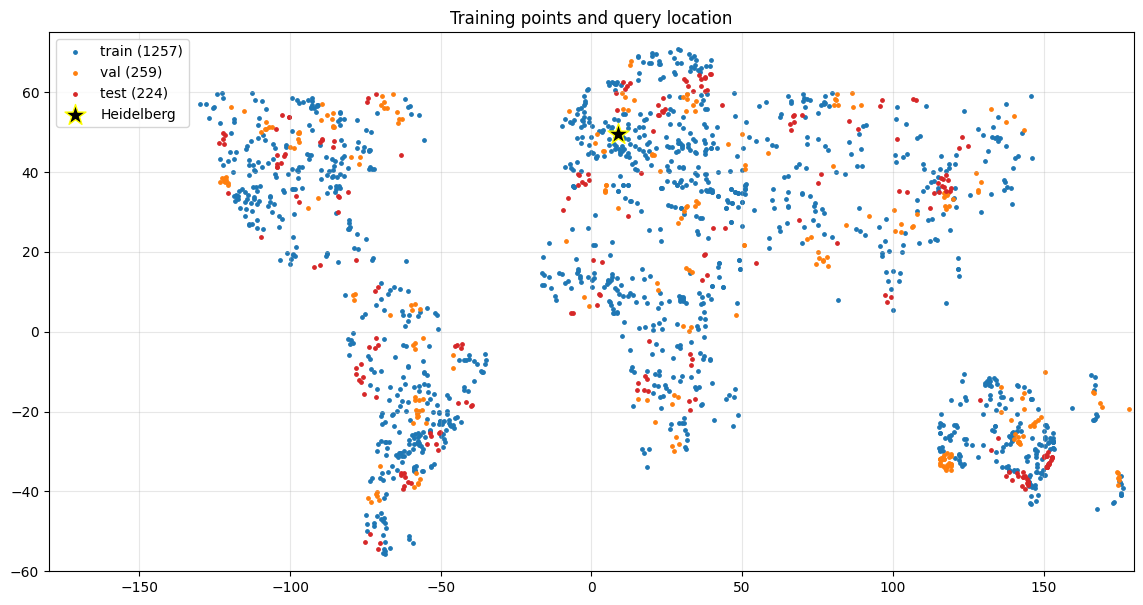

In [4]:
pts = pd.read_json("/content/drive/MyDrive/lulc_s1_global/points.json")
plt.figure(figsize=(14, 7))
for sp, c in [("train", "tab:blue"), ("val", "tab:orange"), ("test", "tab:red")]:
    d = pts[pts.split == sp]; plt.scatter(d.lon, d.lat, s=6, c=c, label=f"{sp} ({len(d)})")
plt.scatter(LON, LAT, s=250, marker="*", c="black", edgecolors="yellow", zorder=5, label="Heidelberg")
plt.xlim(-180, 180); plt.ylim(-60, 75); plt.grid(alpha=.3); plt.legend()
plt.title("Training points and query location"); plt.show()